In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

### Question 1
In lecture and homework we explored how the convolution can be used to calculate the probability of a sum or average. For this problem we are going to imagine that we are looking for gamma-ray sources (e.g. with the Fermi telescope). In this kind of telescope there is a background of cosmic-rays (electrons and protons, mostly) that provides a discrete noise term across the sky that precisely follows a Poisson distribution. To detect a gamma-ray source, you need to ask what is the probability that the cosmic-ray background would have given you a measurement as signal-like or more than the signal that you received.

To set up the problem, assume in 1 day the average cosmic-ray background is some number X (pick someting btwn 0.5 and 10, with different values for you and your lab partner); and the average number of gamma-rays emitted by your hypothetical source is Y (pick something larger than X).

#### Part (a)
Show how the probability distribution of the background changes as you integrate (sum) for more days.

In [2]:
X, Y = 5, 10

In [3]:
#Day 1
k_day1 = np.arange(0, 20)
pmf_day1 = stats.poisson.pmf(k_day1, X)

In [4]:
#Day 2
pmf_day2 = np.convolve(pmf_day1, pmf_day1)
k_day2 = np.arange(0, len(pmf_day2))

In [5]:
#Day 3
pmf_day3 = np.convolve(pmf_day2, pmf_day1)
k_day3 = np.arange(0, len(pmf_day3))

In [6]:
#Day 4
pmf_day4 = np.convolve(pmf_day3, pmf_day1)
k_day4 = np.arange(0, len(pmf_day4))

In [7]:
#Day 5
pmf_day5 = np.convolve(pmf_day4, pmf_day1)
k_day5 = np.arange(0, len(pmf_day5))

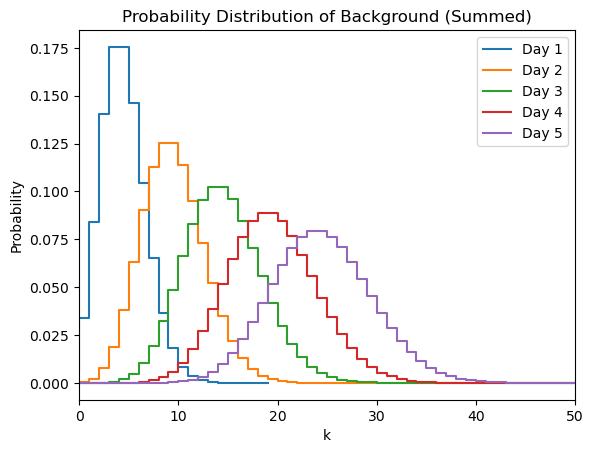

In [8]:
#Plotting probability distribution (summed)
plt.step(k_day1, pmf_day1, label = "Day 1")
plt.step(k_day2, pmf_day2 , label = "Day 2")
plt.step(k_day3, pmf_day3 , label = "Day 3")
plt.step(k_day4, pmf_day4 , label = "Day 4")
plt.step(k_day5, pmf_day5 , label = "Day 5")
plt.xlim(0,50)
plt.xlabel("k")
plt.ylabel("Probability")
plt.title("Probability Distribution of Background (Summed)")
plt.legend()
plt.show()

#### Part (b)
Show that after 5 days, the summed probability distribution is still a Poisson distribution. Explain why this makes sense from a mathematical and conceptual point of view.

In [9]:
#Poisson distribution at 5 days
pois_day5 = stats.poisson.pmf(k_day5, 5 * X)

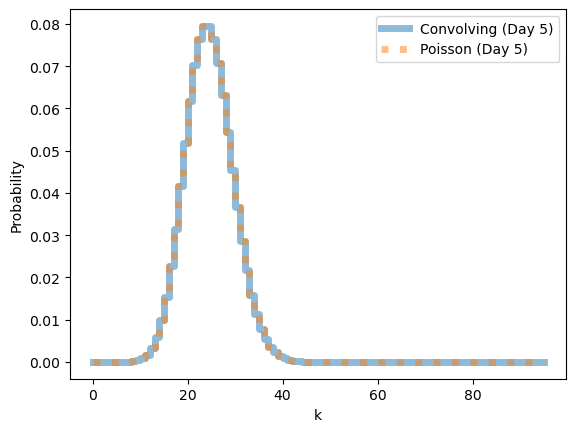

In [10]:
#Plotting the poisson distribution over the convolved distribution
plt.step(k_day5, pmf_day5, alpha = 0.5, linewidth = 5, linestyle = '-', label = "Convolving (Day 5)")
plt.step(k_day5, pois_day5, alpha = 0.5, linewidth = 5, linestyle = ':', label = "Poisson (Day 5)")
plt.xlabel("k")
plt.ylabel("Probability")
plt.legend()
plt.show()

**<u>Mathematical</u>**

Poisson Distribution: $p_i(x) = \frac{\lambda^ke^{-\lambda}}{k!}$

Summing Poisson Distributions: $\sum_{j=1}^{n}p_i(x) = \frac{\lambda^ke^{-n\lambda}}{k!}$ where $n \in \mathbb{Z}^+$

Example: 
$p_1(x) + p_2(x)$ $ = \frac{\lambda^ke^{-\lambda}}{k!} + \frac{\lambda^ke^{-\lambda}}{k!}$ 
$ = \frac{\lambda^k}{k!}(e^{-\lambda} + e^{-\lambda})$
$ = \frac{\lambda^ke^{-2\lambda}}{k!}$


**<u>Conceptually</u>**

If you have a unit thing per unit time (a rate) and want to combine it with a seperate rate of the same units, you get the two rates added together. For instance, my cat eats 5 times per day (Binx...) and my other cat eats 2 times per day (Guen...). Together, they eat 7 times per day.

#### Part (c)
Show how the probability distribution evolves as you average days. Calculate for many different ranges of days, and explore the shape of the distribution as the number of days becomes larger. Discuss this in relation to both B) and the central limit theoem.

In [11]:
#Averages
avg_day1 = k_day1 / 1
avg_day2 = k_day2 / 2
avg_day3 = k_day3 / 3
avg_day4 = k_day4 / 4
avg_day5 = k_day5 / 5

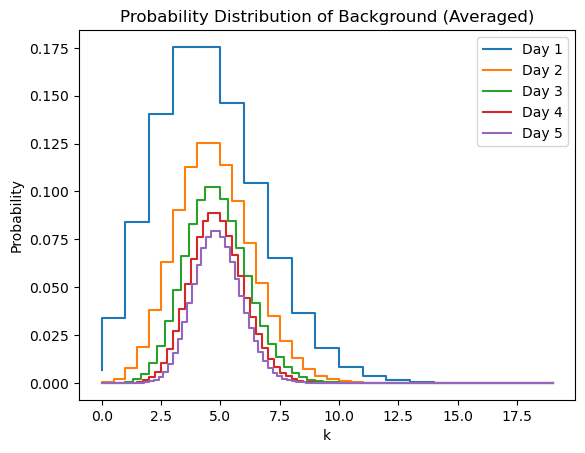

In [12]:
#Plotting probability distribution (average)
plt.step(avg_day1, pmf_day1, label = "Day 1")
plt.step(avg_day2, pmf_day2 , label = "Day 2")
plt.step(avg_day3, pmf_day3 , label = "Day 3")
plt.step(avg_day4, pmf_day4 , label = "Day 4")
plt.step(avg_day5, pmf_day5 , label = "Day 5")
plt.xlabel("k")
plt.ylabel("Probability")
plt.title("Probability Distribution of Background (Averaged)")
plt.legend()
plt.show()

**<u>Width</u>**:
In part (c), we are taking the k-values from part (b) and dividing them by the number of days. The width of the distribution should "shrink" to be the same as day 1. This is seen through each distribution being centered around k = 5.

**<u>Height</u>**:
As seen in part (b), each successive day results in a distribution that is less tall. Since only the k-values are changing, then the heights of distributions should remain the same as in part (b). 

**<u>Central Limit Theorem</u>**:
As number of days increases, the distribution will come closer to a Gaussian distribution (central limit theorem) which is shown in the plot above with each successive day leading to a distribution that is closer to a Gaussian curve.

#### Part (d)
Pick some number of days N, and assume you saw Y*N gamma rays from your source. Calculate the 'sigma' of your observation. [In reality the number of gamma-rays seen from a source will also fluctuate, but we're going to ignore that complication for a couple of labs.]

In [13]:
#Let N = 5 days. (I originally tried 50 and got a quality zero. So it's 5).
X_5 = X * 5
Y_5 = Y * 5

prob_1 = stats.poisson.sf(Y_5, X_5)

print(f"The probability that the observation is background noise is {prob_1}.")

The probability that the observation is background noise is 3.3511409824139397e-06.


In [14]:
sigma_1 = stats.norm.ppf(prob_1)
print(f"The corresponding sigma is {sigma_1: .4f}.")

The corresponding sigma is -4.5029.


### Problem 2
Pick a skewed continuous distribtuion, such as a Rayleigh, that describes your background over some observing interval.

#### Part (a)
Show how the distribution changes as you average over more observing intervals.

In [15]:
#Convolution for a given distribution "n" times
def convolvinator(dist, n):
    dist_n = dist
    for i in range(0, n-1):
        dist_n = np.convolve(dist_n, dist)

    xavg_dayn = np.linspace(0, 20 * n, len(dist_n)) / n
    return xavg_dayn, dist_n

In [16]:
#Gamma distribution with a = 5
a = 5
xavg_day1 = np.linspace(0, 20, 10000)
gamma_day1 = stats.gamma.pdf(xavg_day1, 5)

In [ ]:
#Convolvinator working on days 5, 10, and 30
gamma_day5 = convolvinator(gamma_day1, 5)
gamma_day10 = convolvinator(gamma_day1, 10)
gamma_day30 = convolvinator(gamma_day1, 30)

In [ ]:
#Plotting Day 1
plt.plot(xavg_day1, gamma_day1, label = "Day 1")
plt.legend()
plt.show()

In [ ]:
#Plotting Day 5
plt.plot(gamma_day5[0], gamma_day5[1], label = "Day 5", color = "orange")
plt.legend()
plt.show()

In [ ]:
#Plotting Day 10
plt.plot(gamma_day10[0], gamma_day10[1], label = "Day 10", color = 'green')
plt.legend()
plt.show()

In [ ]:
#Plotting Day 30
plt.plot(gamma_day30[0], gamma_day30[1], label = "Day 30", color = 'red')
plt.legend()
plt.show()

In [ ]:
#Log-scale plot of the four days
plt.plot(xavg_day1, gamma_day1, label = "Day 1")
plt.plot(gamma_day5[0], gamma_day5[1], label = "Day 5")
plt.plot(gamma_day10[0], gamma_day10[1], label = "Day 10")
plt.plot(gamma_day30[0], gamma_day30[1], label = "Day 30")
plt.yscale('log')
plt.legend()
plt.show()

#### Part (b)
Discuss how the shape changes. Does it approach a Gaussian distribution? If yes, after how many intervals?

As the days progress, the average of the Gamma functions become less skewed, grow in drastically in height, and shrink in width. It does approach a Gaussian distribution due to the Central Limit Theorem with the log of the function showing the curve becoming more and more parabolic as the days progress. At 10 days, it looked pretty Gaussian?

### Problem 3
The discovery of optical/infra-red counterparts of Neutron star mergers initially detected with gravity-waves is one of the great discoverys in the last few years (wikipedia, scientific paper), and has ushered in the age of "multi-messenger astrophysics." The science that can be done by matching a gravity-wave signal (directly measures the mass of the neutron stars and their distance) with the optical emisson (redshift, nuclear astrophysics of the resulting explosion) is staggering. Lots of science from how the heaviest elements are formed to constraints on Dark Energy.

We're going to explore one of the analysis questions that comes up when looking for the optical counterparts (a new optical source) of a gravity wave signal. For this problem let's assume that we are using an optical telescope with a thermal noise background from the CCD (dark current, particularly an issue with older CCDs and/or infra-red CCDs). After flat-fielding, the background appears as a zero-mean Gaussian with constant width over the image.

#### Version 1
You have an alert from LIGO that is also seen in with the X-ray/ultra-violet satellite SWIFT. SWIFT gives you a very precise location, so you take an image of that part of the sky. But because of SWIFT's accuracy, you know which pixel in your image to look for a counterpart in.

##### Part (a)
From looking at all the other pixels in your image, you can measure the width of the background Gaussian distribution X (pick something). Assuming you see a signal of strength Y (pick a floating-point number; typical optical CCDs are not sensitive enough to count photons so the readings are floating point brightnesses, not integer photons). Calculate the significance of your detection. Can you claim a discovery (traditionally 5-sigma or more)?

In [ ]:
#Have X = 5 and Y = 33.75
gaus_prob_a = stats.norm.sf(33.75, 0, 5)
sign_a = stats.norm.isf(gaus_prob_a, 0, 1)

print(f"""The significance of a signal strength of 33.75 for a background following X ~ N(0, 5) is to {sign_a:.2f} sigma which is enough to claim a 
discovery (calculated sigma >= 5 sigma)""")

#### Version 2
You have an alert from LIGO, but no associated detection from SWIFT. This could be because it is a black hole-black hole merger, a black hole-neutron star merger (neither seem to emit X-rays or UV light), or it could because SWIFT was indisposed at the time (wrong side of the earth in its orbit). Whatever the cause, you know what region of the sky to look in, but not which pixel.

##### Part (a)
If you have to look for a signal in 10k pixels, what is the probability distribution of your background? (Clearly state the statistical question, then turn that into math using your background distribution from part 1 of this problem.)

**<u>Statistical Question</u>**: What is the background probability distribution for 10k pixels given the background follows a zero-mean Gaussian distribution width and given the width and distribution of a single pixel.

Add each Gaussian on top of each other (like stacking on a histogram), so it's the same normal distribution times 10000

In [ ]:
x_v2 = np.linspace(-50, 50, 10000)
gaus_10000 = 10000 * stats.norm.pdf(x_v2, 0, 5)

In [ ]:
plt.plot(x_v2, gaus_10000)
plt.show()

##### Part (b)
Taking your brightest candidate signal from the region (assume it has the same signal as in part 1), calculate the significance of your detection.

In [ ]:
sign_b = stats.norm.isf(gaus_prob_a * 10000, 0, 1) 
print(f"""The significance of a signal strength of 33.75 is {sign_b:.2f} sigma which is enough to claim a discovery (calculated sigma >= 5 sigma)""")

### Question 4
The statistical issue we were exploring in the previous problem is called a trials factor (sometimes known as a look-elsewhere effect). This is an important effect, as if you search through a million locations, you would expect to see approximately 1 one-in-a-million event. However, it is also often over estimated how big an impact this makes on the sensitivity of a search. So in this part of the lab we are going to invert the problem.

Let us again assume we have a Gaussian background (same parameters as Problem 3).

#### Part (a)
Calculate the signal required for a 5-sigma detection in Version 1

In [ ]:
prob_4a = stats.norm.sf(5, loc=0, scale=1)
sig_v1 = stats.norm.isf(prob_4a, 0, 5)

print(f"The signal required for a 5-sigma detection is {sig_v1:.4f}.")

#### Part (b)
Calculate the signal required for a 5-sigma detection in Version 2

In [ ]:
sig_v2 = stats.norm.isf(prob_4a/10000, 0, 5)

print(f"The signal required for a 5-sigma detection is {sig_v2:.4f}.")

#### Part (c)
Discuss how much brighter the signal must be for discoverey if you have a trials factor of 10k. Looking at your probability distributions, explain why the sensitivity penalty due to a trials factor is so low.

In [ ]:
print(f"The signal must be {sig_v2/sig_v1:.2f} times brighter for a trials factor of 10k compared to a trial factor of 1.")

#### Part (d)
If you changed the trials factor significantly (orders of magnitude), how large is the effect on your 5-sigma sensitivity threshold?

In [ ]:
sig_vlarge = stats.norm.isf(prob_4a/1000000, 0, 5)

In [ ]:
print(f"""As the trials factor significantly increases, the 5-sigma threshold increases, though the effect on the threshold is remarkably small. 
For instance, 10k: 1 is {sig_v2/sig_v1:.2f}:1 while 1 million: 1 is {sig_vlarge/sig_v1:.2f}:1""")

#### Part (e) (Extra Credit)
If you had a different distribution shape (non-Gaussian), how would that affect the sensitivity penalty of many trials? Clearly explain.